In [2]:
from pathlib import Path
import pandas as pd

RAW = Path("../data/raw")

tables = {
    p.stem.replace("olist_", "").replace("_dataset", ""): pd.read_csv(p)
    for p in RAW.glob("*.csv")
}

print(list(tables.keys()))

['customers', 'geolocation', 'orders', 'order_items', 'order_payments', 'order_reviews', 'products', 'sellers', 'product_category_name_translation']


In [3]:
summary = pd.DataFrame({
    "rows": {name: len(df) for name, df in tables.items()},
    "columns": {name: df.shape[1] for name, df in tables.items()},
})
summary

,rows,columns
customers,99441,5
geolocation,1000163,5
orders,99441,8
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
products,32951,9
sellers,3095,4
product_category_name_translation,71,2


In [4]:
for name, df in tables.items():
    nulls = (df.isna().mean() * 100).round(2)
    nulls = nulls[nulls > 0]
    if len(nulls):
        print(f"\n{name}")
        print(nulls.sort_values(ascending=False).to_string())


orders
order_delivered_customer_date    2.98
order_delivered_carrier_date     1.79
order_approved_at                0.16

order_reviews
review_comment_title      88.34
review_comment_message    58.70

products
product_category_name         1.85
product_name_lenght           1.85
product_description_lenght    1.85
product_photos_qty            1.85
product_weight_g              0.01
product_length_cm             0.01
product_height_cm             0.01
product_width_cm              0.01


In [5]:
orders = tables["orders"].copy()

date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

print(orders["order_status"].value_counts())
print()
print("First order: ", orders["order_purchase_timestamp"].min())
print("Last order: ", orders["order_purchase_timestamp"].max())
orders.dtypes

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

First order:  2016-09-04 21:15:19
Last order:  2018-10-17 17:30:18


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [6]:
customers = tables["customers"]
items = tables["order_items"]
payments = tables["order_payments"]
reviews = tables ["order_reviews"]

print("order rows:                      ", len(orders))
print("unique order_id:                 ", orders["order_id"].nunique())
print()
print("Customers rows:                  ", len(customers))
print("unique customer_id:              ", customers["customer_id"].nunique())
print("unique customer_unique_id:       ", customers["customer_unique_id"].nunique())
print()
print("orders with no items:            ", (~orders["order_id"].isin(items["order_id"])).sum())
print("orders with no payment:          ", (~orders["order_id"].isin(payments["order_id"])).sum())
print("order with >1 review:            ", (reviews["order_id"].value_counts() > 1).sum())

order rows:                       99441
unique order_id:                  99441

Customers rows:                   99441
unique customer_id:               99441
unique customer_unique_id:        96096

orders with no items:             775
orders with no payment:           1
order with >1 review:             547


In [7]:
delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]
).copy()

delivered["delay_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_estimated_delivery_date"]
).dt.days

print("Share delivered late:", round((delivered["delay_days"] > 0).mean() * 100, 1), "%")
print(delivered["delay_days"].describe())

Share delivered late: 6.8 %
count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delay_days, dtype: float64


month
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Freq: M, Name: price, dtype: float64

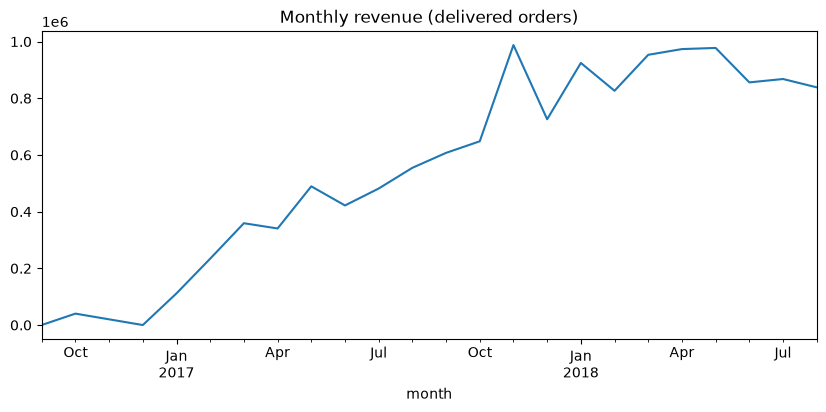

In [8]:
rev = items.merge(
    orders[["order_id", "order_status", "order_purchase_timestamp"]],
    on="order_id",
)
rev = rev[rev["order_status"] == "delivered"]
rev["month"] = rev["order_purchase_timestamp"].dt.to_period("M")

monthly = rev.groupby("month")["price"].sum()
monthly.plot(figsize=(10,4), title="Monthly revenue (delivered orders)")
monthly.tail(8)

In [9]:
tables["orders"].info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [10]:
tables["order_items"].info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [11]:
items_per_order = items.groupby("order_id")["order_item_id"].count()
items_per_order.value_counts().sort_index()


order_item_id
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [12]:
orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size().tail(14)

#monthly_orders = orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size()

#avg_orders = monthly_orders.loc["2017-09":"2018-08"].mean()
#print("Month orders average: ", round(avg_orders, 2))

order_purchase_timestamp
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64

In [13]:
nov = orders[orders["order_purchase_timestamp"].dt.to_period("M") == "2017-11"]
nov.groupby(nov["order_purchase_timestamp"].dt.date).size().sort_values(ascending=False).head(5)

order_purchase_timestamp
2017-11-24    1176
2017-11-25     499
2017-11-27     403
2017-11-26     391
2017-11-28     380
dtype: int64

In [14]:
o = orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id")
per_customer = o.groupby("customer_unique_id")["order_id"].nunique()

print("Customers: ", len(per_customer))
print("Repeat customers: ", (per_customer > 1).sum())
print("Repeat rate: ", round((per_customer > 1).mean()* 100,2),"%")

Customers:  96096
Repeat customers:  2997
Repeat rate:  3.12 %


In [15]:
no_items = ~orders["order_id"].isin(items["order_id"])
pd.crosstab(orders["order_status"], no_items)

order_id,False,True
order_status,,
approved,2,0
canceled,461,164
created,0,5
delivered,96478,0
invoiced,312,2
processing,301,0
shipped,1106,1
unavailable,6,603


In [16]:
delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]
).copy()

delivered["delay_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_estimated_delivery_date"]
).dt.days

print("Share delivered late:", round((delivered["delay_days"] >0).mean() * 100, 1), "%")
print(delivered["delay_days"].describe())

Share delivered late: 6.8 %
count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delay_days, dtype: float64


In [17]:
recent = orders[orders["order_purchase_timestamp"] >= "2018-08-01"]
daily = recent.groupby(recent["order_purchase_timestamp"].dt.date).size()
daily.tail(30)

order_purchase_timestamp
2018-08-17    257
2018-08-18    198
2018-08-19    204
2018-08-20    256
2018-08-21    243
2018-08-22    187
2018-08-23    144
2018-08-24     99
2018-08-25     69
2018-08-26     73
2018-08-27     67
2018-08-28     44
2018-08-29     14
2018-08-30      4
2018-08-31      1
2018-09-03      4
2018-09-06      3
2018-09-10      1
2018-09-11      1
2018-09-12      1
2018-09-13      1
2018-09-17      1
2018-09-20      1
2018-09-25      1
2018-09-26      1
2018-09-29      1
2018-10-01      1
2018-10-03      1
2018-10-16      1
2018-10-17      1
dtype: int64

In [19]:
late = orders[orders["order_purchase_timestamp"] >= "2018-09-01"]
late[["order_status", "order_purchase_timestamp"]].sort_values("order_purchase_timestamp")

,order_status,order_purchase_timestamp
62360,shipped,2018-09-03 09:06:57
39919,canceled,2018-09-03 14:14:25
24410,canceled,2018-09-03 18:40:50
73341,canceled,2018-09-03 18:45:34
53501,canceled,2018-09-06 10:48:12
20778,canceled,2018-09-06 14:50:07
99347,canceled,2018-09-06 18:45:47
31170,canceled,2018-09-10 17:51:25
9976,canceled,2018-09-11 16:45:54
80019,canceled,2018-09-12 15:32:16


In [20]:
orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size().head(8)

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
Freq: M, dtype: int64